# Data Preprocessing

In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

In [2]:
files = Path("../data/raw").glob("*.csv")

data = pd.concat(
    [pd.read_csv(file, sep=";") for file in files],
    ignore_index=True
)

In [3]:
data.head()

,betriebstag,fahrt_bezeichner,betreiber_id,betreiber_abk,betreiber_name,produkt_id,linien_id,linien_text,umlauf_id,verkehrsmittel_text,...,an_prognose,an_prognose_status,abfahrtszeit,ab_prognose,ab_prognose_status,durchfahrt_tf,sloid,ankunftsverspatung,an_versp_sek,abfahrtsverspatung
0,2026-11-01,ch:1:sjyid:100001:25791-001,85:11,SBB,Schweizerische Bundesbahnen SBB,Zug,25791,S10,NaN,S,...,2026-11-01T22:50:40,REAL,2026-11-01T22:53:00,2026-11-01T22:53:11,REAL,False,ch:1:sloid:5214,False,-40.0,False
1,2026-11-01,ch:1:sjyid:100001:25791-001,85:11,SBB,Schweizerische Bundesbahnen SBB,Zug,25791,S10,NaN,S,...,2026-11-01T23:04:00,REAL,2026-11-01T23:06:00,2026-11-01T23:06:12,REAL,False,ch:1:sloid:5300,False,60.0,False
2,2026-11-01,ch:1:sjyid:100001:25792-001,85:11,SBB,Schweizerische Bundesbahnen SBB,Zug,25792,S10,NaN,S,...,2026-11-01T01:22:24,REAL,2026-11-01T01:22:00,2026-11-01T01:23:06,REAL,False,ch:1:sloid:5214,False,-84.0,False
3,2026-11-01,ch:1:sjyid:100001:25804-001,85:11,SBB,Schweizerische Bundesbahnen SBB,Zug,25804,RE80,NaN,RE,...,2026-11-01T06:50:26,REAL,2026-11-01T06:50:00,NaN,PROGNOSE,False,ch:1:sloid:5404,False,-26.0,False
4,2026-11-01,ch:1:sjyid:100001:25804-001,85:11,SBB,Schweizerische Bundesbahnen SBB,Zug,25804,RE80,NaN,RE,...,NaN,UNBEKANNT,2026-11-01T06:57:00,NaN,UNBEKANNT,False,ch:1:sloid:5402,False,NaN,False


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 493441 entries, 0 to 493440
Data columns (total 25 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   betriebstag          493441 non-null  object 
 1   fahrt_bezeichner     493441 non-null  object 
 2   betreiber_id         493441 non-null  object 
 3   betreiber_abk        493441 non-null  object 
 4   betreiber_name       493441 non-null  object 
 5   produkt_id           493441 non-null  object 
 6   linien_id            493441 non-null  int64  
 7   linien_text          493439 non-null  object 
 8   umlauf_id            0 non-null       float64
 9   verkehrsmittel_text  493439 non-null  object 
 10  zusatzfahrt_tf       493441 non-null  bool   
 11  faellt_aus_tf        493441 non-null  bool   
 12  bpuic                493441 non-null  float64
 13  haltestellen_name    493441 non-null  object 
 14  ankunftszeit         452646 non-null  object 
 15  an_prognose      

### Temporal and record coverage

In [5]:
# date range of the dataset
print("First operating day:", data["betriebstag"].min())
print("Last operating day:", data["betriebstag"].max())
print("Number of operating days:", data["betriebstag"].nunique())

First operating day: 2026-11-01
Last operating day: 2026-11-07
Number of operating days: 7


In [6]:
# number of stop records, train runs, lines and stations per operating day
daily_summary = (
    data.groupby("betriebstag")
    .agg(
        stop_records = ("fahrt_bezeichner", "size"),
        train_runs = ("fahrt_bezeichner", "nunique"),
        lines = ("linien_text", "nunique"),
        stations = ("haltestellen_name", "nunique")
    )
)

daily_summary

,stop_records,train_runs,lines,stations
betriebstag,,,,
2026-11-01,68284,5563,111,860
2026-11-02,70573,5860,105,916
2026-11-03,70825,5896,106,918
2026-11-04,70765,5883,105,915
2026-11-05,70468,5836,105,907
2026-11-06,71384,5931,112,919
2026-11-07,71142,5810,115,855


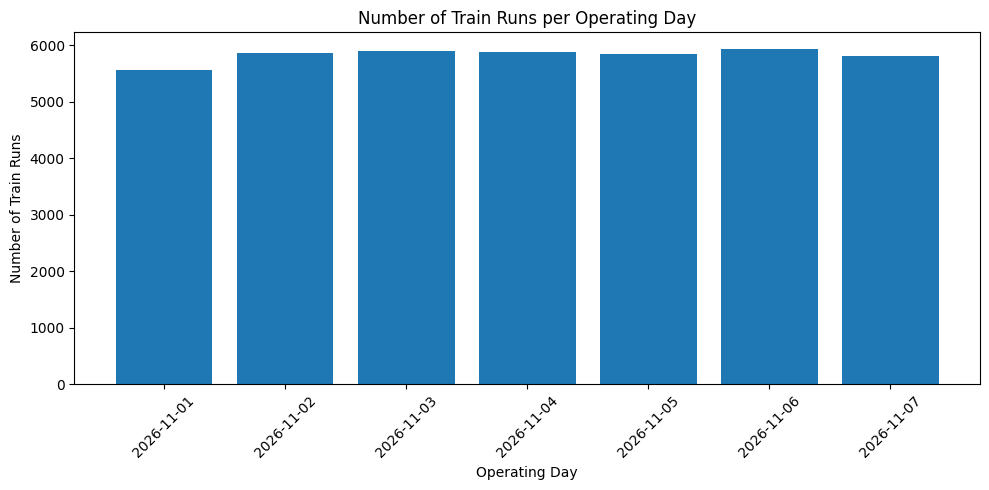

In [7]:
plt.figure(figsize=(10, 5))
plt.bar(daily_summary.index.astype(str),daily_summary["train_runs"])
plt.title("Number of Train Runs per Operating Day")
plt.xlabel("Operating Day")
plt.ylabel("Number of Train Runs")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Variable Types

In [8]:
# time columns to datetime
date_cols = ["ankunftszeit", "an_prognose", "abfahrtszeit", "ab_prognose"]

for col in date_cols:
    # convert to datetime
    parsed = pd.to_datetime(
        data[col],
        format="%Y-%m-%dT%H:%M:%S",
        errors="coerce"
    )
    
    # Show non-null values that could not be converted
    invalid_rows = data[data[col].notna() & parsed.isna()]
    print(invalid_rows[[col]])

    data[col] = parsed

Empty DataFrame
Columns: [ankunftszeit]
Index: []
Empty DataFrame
Columns: [an_prognose]
Index: []
Empty DataFrame
Columns: [abfahrtszeit]
Index: []
Empty DataFrame
Columns: [ab_prognose]
Index: []


In [9]:
# date column to datetime
parsed = pd.to_datetime(data["betriebstag"])

# Show non-null values that could not be converted
invalid_rows = data[data["betriebstag"].notna() & parsed.isna()]
print(invalid_rows[["betriebstag"]])

data["betriebstag"] = parsed

Empty DataFrame
Columns: [betriebstag]
Index: []


In [10]:
# delete empty column
data.pop("umlauf_id");

In [11]:
# all trains are operated by SBB, so we can remove this column
print(all(data["betreiber_abk"] == "SBB"))

operator_cols = ["betreiber_id", "betreiber_abk", "betreiber_name"]
data.drop(columns = operator_cols, inplace = True)

True


In [12]:
# trains are the only vehicles used
print(all(data["produkt_id"] == "Zug"))

data.drop(columns = "produkt_id", inplace = True)

True


In [13]:
# compute delay in minutes (for eda)
data["an_versp_min"] = data["an_versp_sek"] / 60

In [14]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 493441 entries, 0 to 493440
Data columns (total 21 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   betriebstag          493441 non-null  datetime64[ns]
 1   fahrt_bezeichner     493441 non-null  object        
 2   linien_id            493441 non-null  int64         
 3   linien_text          493439 non-null  object        
 4   verkehrsmittel_text  493439 non-null  object        
 5   zusatzfahrt_tf       493441 non-null  bool          
 6   faellt_aus_tf        493441 non-null  bool          
 7   bpuic                493441 non-null  float64       
 8   haltestellen_name    493441 non-null  object        
 9   ankunftszeit         452646 non-null  datetime64[ns]
 10  an_prognose          423457 non-null  datetime64[ns]
 11  an_prognose_status   455044 non-null  object        
 12  abfahrtszeit         452629 non-null  datetime64[ns]
 13  ab_prognose   

## Delays Outlier Detection

In [15]:
delay_summary = pd.DataFrame({
    "metric": ["Observed arrival delays", "Early arrivals", "On-time or early arrivals", "Late arrivals",
               "More than 3 minutes late", "More than 5 minutes late", "More than 10 minutes late", "More than 15 minutes late"],
    "value": [data["an_versp_min"].notna().sum(), (data["an_versp_min"] < 0).sum(), (data["an_versp_min"] <= 0).sum(),
              (data["an_versp_min"] > 0).sum(), (data["an_versp_min"] > 3).sum(), (data["an_versp_min"] > 5).sum(),
              (data["an_versp_min"] > 10).sum(), (data["an_versp_min"] > 15).sum()]
})
delay_summary

,metric,value
0,Observed arrival delays,423457
1,Early arrivals,305615
2,On-time or early arrivals,317603
3,Late arrivals,105854
4,More than 3 minutes late,375
5,More than 5 minutes late,80
6,More than 10 minutes late,18
7,More than 15 minutes late,8


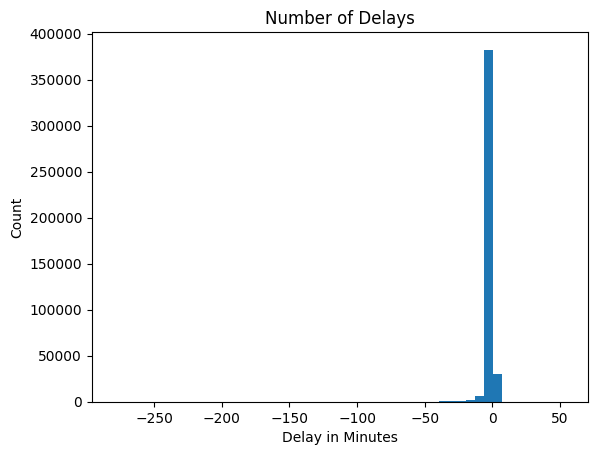

In [16]:
plt.hist(data["an_versp_min"], bins = 50)
plt.title("Number of Delays")
plt.xlabel("Delay in Minutes")
plt.ylabel("Count")
plt.show()

In [17]:
sum(data["an_versp_min"] < -120)

70

In [18]:
data[data["an_versp_min"] < -120].sort_values(by="an_versp_min")

,betriebstag,fahrt_bezeichner,linien_id,linien_text,verkehrsmittel_text,zusatzfahrt_tf,faellt_aus_tf,bpuic,haltestellen_name,ankunftszeit,...,an_prognose_status,abfahrtszeit,ab_prognose,ab_prognose_status,durchfahrt_tf,sloid,ankunftsverspatung,an_versp_sek,abfahrtsverspatung,an_versp_min
235155,2026-11-06,ch:1:sjyid:100001:401-009,401,EN,EN,False,False,8505300.0,Lugano,2026-11-06 09:40:00,...,REAL,2026-11-06 09:41:00,2026-11-06 14:27:50,REAL,False,ch:1:sloid:5300,True,-16764.0,True,-279.400000
275940,2026-11-06,ch:1:sjyid:100001:401-009,401,EN,EN,False,False,8505119.0,Göschenen,2026-11-06 07:30:00,...,REAL,2026-11-06 07:58:00,2026-11-06 12:07:16,REAL,False,ch:1:sloid:5119,True,-16256.0,True,-270.933333
275939,2026-11-06,ch:1:sjyid:100001:401-009,401,EN,EN,False,False,8502113.0,Aarau,2026-11-06 05:38:00,...,REAL,2026-11-06 05:40:00,2026-11-06 09:59:01,REAL,False,ch:1:sloid:2113,True,-15565.0,True,-259.416667
218807,2026-11-06,ch:1:sjyid:100001:401-009,401,EN,EN,False,False,8505004.0,Arth-Goldau,2026-11-06 06:33:00,...,REAL,2026-11-06 06:35:00,2026-11-06 10:55:39,REAL,False,ch:1:sloid:5004,True,-15564.0,True,-259.400000
235154,2026-11-06,ch:1:sjyid:100001:401-009,401,EN,EN,False,False,8505213.0,Bellinzona,2026-11-06 09:06:00,...,REAL,2026-11-06 09:08:00,2026-11-06 13:23:34,REAL,False,ch:1:sloid:5213,True,-15274.0,True,-254.566667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
419568,2026-11-05,ch:1:sjyid:100001:403-001,403,NJ,NJ,False,False,8500010.0,Basel SBB,2026-11-05 06:21:00,...,REAL,2026-11-05 06:38:00,2026-11-05 08:56:04,REAL,False,ch:1:sloid:10,True,-7680.0,True,-128.000000
419569,2026-11-05,ch:1:sjyid:100001:403-001,403,NJ,NJ,False,False,8503000.0,Zürich HB,2026-11-05 08:05:00,...,REAL,NaT,NaT,NaN,False,ch:1:sloid:3000,True,-7592.0,False,-126.533333
405393,2026-11-05,ch:1:sjyid:100001:403-001,403,NJ,NJ,False,False,8014350.0,Freiburg(Breisgau) Hbf,2026-11-05 05:26:00,...,PROGNOSE,2026-11-05 05:28:00,2026-11-05 07:35:00,PROGNOSE,False,NaN,True,-7560.0,True,-126.000000
400454,2026-11-05,ch:1:sjyid:100001:106-002,106,ICE,ICE,False,False,8008094.0,Düsseldorf Hbf,2026-11-05 17:32:00,...,PROGNOSE,2026-11-05 17:34:00,2026-11-05 19:42:00,PROGNOSE,False,NaN,True,-7560.0,True,-126.000000


When examining the trains that arrived way ahead of schedule, most of them are EN or NJ which are both international overnight trains. Since those are often scheduled to wait at certain stops so that travelers arrive in the morning, these delays seem realistic. 

## Data completeness and cancellations

In [19]:
# missing values in the most relevant time and delay columns
missing_values = data[["ankunftszeit", "an_prognose", "abfahrtszeit", "ab_prognose", "an_versp_sek", "an_versp_min"]].isna().sum()
print(missing_values)

ankunftszeit    40795
an_prognose     69984
abfahrtszeit    40812
ab_prognose     70167
an_versp_sek    69984
an_versp_min    69984
dtype: int64


In [20]:
# number and percentage of cancelled, additional and pass-through records
special_records = pd.DataFrame({
    "count": [data["faellt_aus_tf"].sum(), data["zusatzfahrt_tf"].sum(), data["durchfahrt_tf"].sum()],
    "percentage": [data["faellt_aus_tf"].mean() * 100, data["zusatzfahrt_tf"].mean() * 100, data["durchfahrt_tf"].mean() * 100]},
index = ["Cancelled records", "Additional-service records", "Pass-through records"])

special_records.round(2)

,count,percentage
Cancelled records,21807,4.42
Additional-service records,7160,1.45
Pass-through records,317,0.06


## Decide on a subnetwork for the optimisation problem
Looking at the plan in figures, most trains run between Bern and Zürich. We could focus on this line or extend the subnetwork a bit to cover all connections between Bern, Zürich and Basel.

In [34]:
stops_choice = ["Bern", "Burgdorf", "Wynigen", "Herzogenbuchsee", "Langenthal", "Olten", 
                "Aarau", "Lenzburg", "Brugg AG", "Baden", "Dietikon", "Zürich Altstetten", "Zürich HB"]

# only keep trains that serviced at least 2 stops between Zürich and Bern
temp = data.loc[
    data["haltestellen_name"].isin(stops_choice)
].copy()

n_chosen_stops = (
    temp
    .groupby(["betriebstag", "fahrt_bezeichner"])["haltestellen_name"]
    .nunique()
)

valid_journeys = n_chosen_stops.loc[
    n_chosen_stops >= 2
].index

journey_index = pd.MultiIndex.from_frame(
    temp[["betriebstag", "fahrt_bezeichner"]]
)

data_subnetwork = temp.loc[
    journey_index.isin(valid_journeys)
].copy()

In [35]:
missing_summary = (
    data_subnetwork
    .groupby("haltestellen_name")
    .agg(
        n_observations=("haltestellen_name", "size"),
        n_missing_versp=(
            "an_versp_min",
            lambda x: x.isna().sum()
        )
    )
    .reindex(stops_choice, fill_value=0)
)

missing_summary["pct_missing"] = (
    100
    * missing_summary["n_missing_versp"]
    / missing_summary["n_observations"]
)

print(missing_summary)

                   n_observations  n_missing_versp  pct_missing
haltestellen_name                                              
Bern                         1678              548    32.657926
Burgdorf                      117                0     0.000000
Wynigen                        11                0     0.000000
Herzogenbuchsee               117                0     0.000000
Langenthal                    651              274    42.089094
Olten                        3307              661    19.987904
Aarau                        3058              500    16.350556
Lenzburg                     1690               48     2.840237
Brugg AG                     2463              366    14.859927
Baden                        2499              449    17.967187
Dietikon                     1751              138     7.881211
Zürich Altstetten            2926               69     2.358168
Zürich HB                    5707              949    16.628702


In [36]:
print("Rows in original data:", len(data))
print("Rows in subnetwork:", len(data_subnetwork))

print(
    "Unique train runs in subnetwork:",
    data_subnetwork[["betriebstag", "fahrt_bezeichner"]]
    .drop_duplicates()
    .shape[0]
)

Rows in original data: 493441
Rows in subnetwork: 25975
Unique train runs in subnetwork: 8055


In [37]:
# export data
data_subnetwork.to_pickle("../data/processed/subnetwork.pkl")